#### **Libraries and modules**

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from datetime import datetime
from cmcrameri import cm as cmc

#### **Load AIFS-ENS and ERA5 data**

In [2]:
# Load AIFS dataset
AIFS_filename_pl = "AIFS-ENS_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_AIFS_pl = xr.open_dataset(AIFS_filename_pl)

# Load ERA5 dataset
ERA5_filename_pl = "ERA5_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_ERA5_pl = xr.open_dataset(ERA5_filename_pl)


#### **Convert Specific Humidity from kg kg⁻¹ to g kg⁻¹ in the xarray dataset**


In [3]:
# Specific humidity at pressure levels AIFS
# Convert from kg kg^-1 to g kg^-1
ds_AIFS_pl["specific_humidity_in_g_per_kg"] = (
    ds_AIFS_pl["q"] * 1000.0
)

ds_AIFS_pl["specific_humidity_in_g_per_kg"].attrs = {
    "long_name": "Specific Humidity",
    "units": "g kg^-1",
    "standard_name": "specific_humidity"
}

# Specific humidity at pressure levels ERA5
# Convert from kg kg^-1 to g kg^-1
ds_ERA5_pl["specific_humidity_in_g_per_kg"] = (
    ds_ERA5_pl["q"] * 1000.0
)

ds_ERA5_pl["specific_humidity_in_g_per_kg"].attrs = {
    "long_name": "Specific Humidity",
    "units": "g kg^-1",
    "standard_name": "specific_humidity"
}


#### **Select the target time (valid time of forecast)**

In [5]:
target_time = pd.to_datetime("2025-11-17_18UTC", format="%Y-%m-%d_%HUTC")

#### **Locate Maximum Specific Humidity in ERA5**


In [6]:
# Maximum specific humidity at 500 hPa in ERA5
specific_humidity_max_500hPa_ERA5_pl = (
    ds_ERA5_pl["specific_humidity_in_g_per_kg"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze(drop=True)
)

# Find the maximum and its location
specific_humidity_500hPa_ERA5_stacked = (
    specific_humidity_max_500hPa_ERA5_pl.stack(
        gridpoint=(
            "latitude",
            "longitude"
        )
    )
)

specific_humidity_max_index_500hPa_ERA5_pl = int(
    specific_humidity_500hPa_ERA5_stacked.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

specific_humidity_max_point_500hPa_ERA5_pl = (
    specific_humidity_500hPa_ERA5_stacked.isel(
        gridpoint=(
            specific_humidity_max_index_500hPa_ERA5_pl
        )
    )
)

lat_max_500hPa_ERA5_pl = float(
    specific_humidity_max_point_500hPa_ERA5_pl[
        "latitude"
    ].values
)

lon_max_500hPa_ERA5_pl = float(
    specific_humidity_max_point_500hPa_ERA5_pl[
        "longitude"
    ].values
)

specific_humidity_max_500hPa_ERA5_pl_value = float(
    specific_humidity_max_point_500hPa_ERA5_pl.values
)

print(
    "ERA5 Maximum Specific Humidity at 500 hPa: "
    f"{specific_humidity_max_500hPa_ERA5_pl_value:.2f} g kg^-1"
)

print(
    "Location (Lat, Lon): "
    f"({lat_max_500hPa_ERA5_pl:.2f}, "
    f"{lon_max_500hPa_ERA5_pl:.2f})"
)


ERA5 Maximum Specific Humidity at 500 hPa: 2.73 g kg^-1
Location (Lat, Lon): (-42.75, -55.00)


#### **Subset AIFS Specific Humidity at the Location of the ERA5 Maximum**


In [7]:
# Convert longitude from the ERA5 to the AIFS convention
# (0 to 360 degrees) for 500 hPa
lon_max_aifs_500pl = lon_max_500hPa_ERA5_pl % 360

# Find the closest forecast time in AIFS to the target time
target_time = np.datetime64("2025-11-17T18:00:00")
lead_idx = int(
    np.argmin(
        np.abs(
            ds_AIFS_pl["fc_valid_time"].values
            - target_time
        )
    )
)
lead_sel = ds_AIFS_pl["leadtime"].values[lead_idx]

# Extract the specific humidity at 500 hPa at the ERA5 maximum
# location for the selected lead time
aifs_specific_humidity_extreme_loc = (
    ds_AIFS_pl["specific_humidity_in_g_per_kg"]
    .sel(
        isobaricInhPa=500,
        latitude=lat_max_500hPa_ERA5_pl,
        longitude=lon_max_aifs_500pl,
        leadtime=lead_sel,
        method="nearest"
    )
)

# Select the nearest AIFS grid point at the ERA5 500 hPa
# maximum location for the selected lead time
aifs_point = ds_AIFS_pl.sel(
    isobaricInhPa=500,
    latitude=lat_max_500hPa_ERA5_pl,
    longitude=lon_max_aifs_500pl,
    leadtime=lead_sel,
    method="nearest"
)

# Select AIFS specific humidity at the ERA5 maximum location
# for all lead times
ds_AIFS_pl_sel_specific_humidity = (
    ds_AIFS_pl["specific_humidity_in_g_per_kg"]
    .sel(
        isobaricInhPa=500,
        latitude=lat_max_500hPa_ERA5_pl,
        longitude=lon_max_aifs_500pl,
        method="nearest"
    )
)


## **Plotting**

#### **Set output directory for all plots**

In [8]:
# Default output directory for all plots
PLOT_DIR = Path(
    r"C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc"
    r"\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks"
    r"\01_Case_Study\01_Code\01_Plots\03_specific_humidity"
)

def save_plot(
    fig,
    plot_name,
    output_dir=PLOT_DIR,
    dpi=300
):
    """
    Save a Matplotlib figure as both PNG and PDF.

    PNG files are saved in:
        output_dir/png

    PDF files are saved in:
        output_dir/pdf

    Files are named:
        YYYYMMDD_specific_humidity_plot_name.png
        YYYYMMDD_specific_humidity_plot_name.pdf

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure that should be saved.
    plot_name : str
        Descriptive filename without the date or file extension.
    output_dir : str or pathlib.Path
        Main directory containing the PNG and PDF subfolders.
    dpi : int
        Resolution of the PNG file.
    """

    output_dir = Path(output_dir)

    # Separate output directories
    png_dir = output_dir / "01_png"
    pdf_dir = output_dir / "02_pdf"

    # Create directories if they do not already exist
    png_dir.mkdir(parents=True, exist_ok=True)
    pdf_dir.mkdir(parents=True, exist_ok=True)

    current_date = datetime.now().strftime("%Y%m%d")

    # Prevent unwanted spaces in filenames
    clean_plot_name = plot_name.strip().replace(" ", "_")

    filename = (
        f"{current_date}_specific_humidity_"
        f"{clean_plot_name}"
    )

    png_path = png_dir / f"{filename}.png"
    pdf_path = pdf_dir / f"{filename}.pdf"

    # High-resolution raster image
    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight"
    )

    # Vector image
    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    print(
        "Plots saved as:\n"
        f"PNG: {png_path}\n"
        f"PDF: {pdf_path}"
    )

    return png_path, pdf_path


### **Boxplots**

#### **Boxplot Comparing AIFS Ensemble 500 hPa Specific Humidity with Maximum 500 hPa Specific Humidity in ERA5**  


Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\03_specific_humidity\01_png\20260723_specific_humidity_boxplot_500hPa_AIFS_ERA5_max.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\03_specific_humidity\02_pdf\20260723_specific_humidity_boxplot_500hPa_AIFS_ERA5_max.pdf


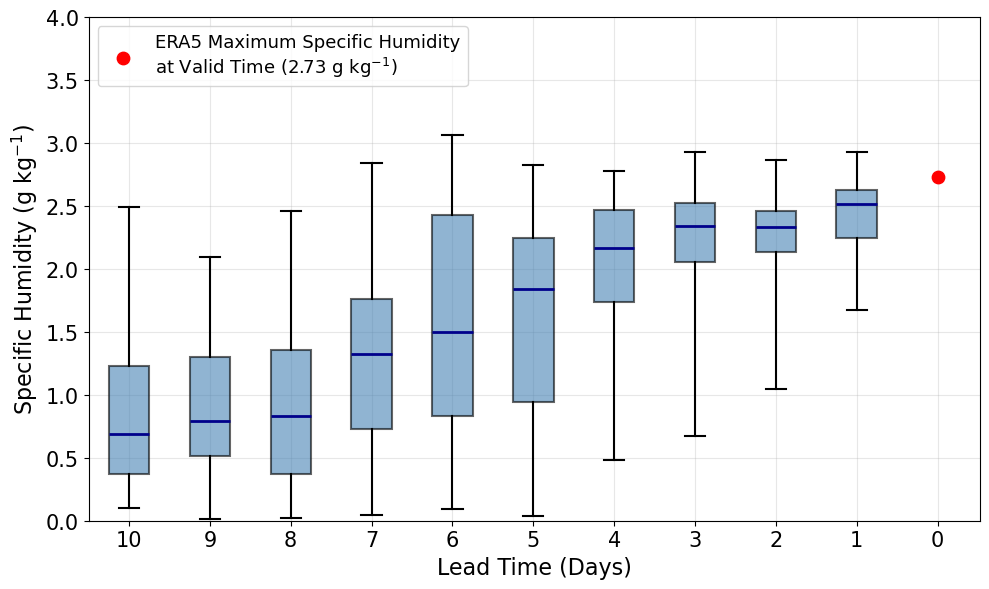

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

leadtimes = np.arange(1, 10 + 1, 1)
n_leads = len(leadtimes)

# Reverse data so lead time 10 days appears first
data_reversed = (
    ds_AIFS_pl_sel_specific_humidity.values[:, ::-1]
)

box = ax.boxplot(
    data_reversed,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="steelblue",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkblue",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum 500 hPa specific humidity
ax.scatter(
    n_leads + 1,
    specific_humidity_max_500hPa_ERA5_pl_value,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Specific Humidity\n"
        f"at Valid Time "
        f"({specific_humidity_max_500hPa_ERA5_pl_value:.2f} "
        "g kg$^{-1}$)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtimes[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(
    ds_AIFS_pl_sel_specific_humidity[
        "fc_valid_time"
    ].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel(
    "Specific Humidity (g kg$^{-1}$)",
    fontsize=16
)

# Fixed y-axis limits
specific_humidity_step = 0.5
specific_humidity_low = 0.0
specific_humidity_high = 4.0

ax.set_ylim(
    specific_humidity_low,
    specific_humidity_high
)

ax.set_yticks(
    np.arange(
        specific_humidity_low,
        specific_humidity_high + 0.1,
        specific_humidity_step
    )
)

ax.legend(fontsize=13, loc="upper left")
ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_500hPa_AIFS_ERA5_max"
)

plt.show()
plt.close(fig)

#### **Boxplot Comparing AIFS Ensemble 500 hPa Specific Humidity with Maximum 500 hPa Specific Humidity in ERA5 with Spatial Shift Allowance – AIFS Finds Maximum Specific Humidity within ±2.0° Lat, ±2.0° Lon of the ERA5 Maximum Location**


Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\03_specific_humidity\01_png\20260723_specific_humidity_boxplot_500hPa_AIFS_ERA5_max_spatial_allowance.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\03_specific_humidity\02_pdf\20260723_specific_humidity_boxplot_500hPa_AIFS_ERA5_max_spatial_allowance.pdf


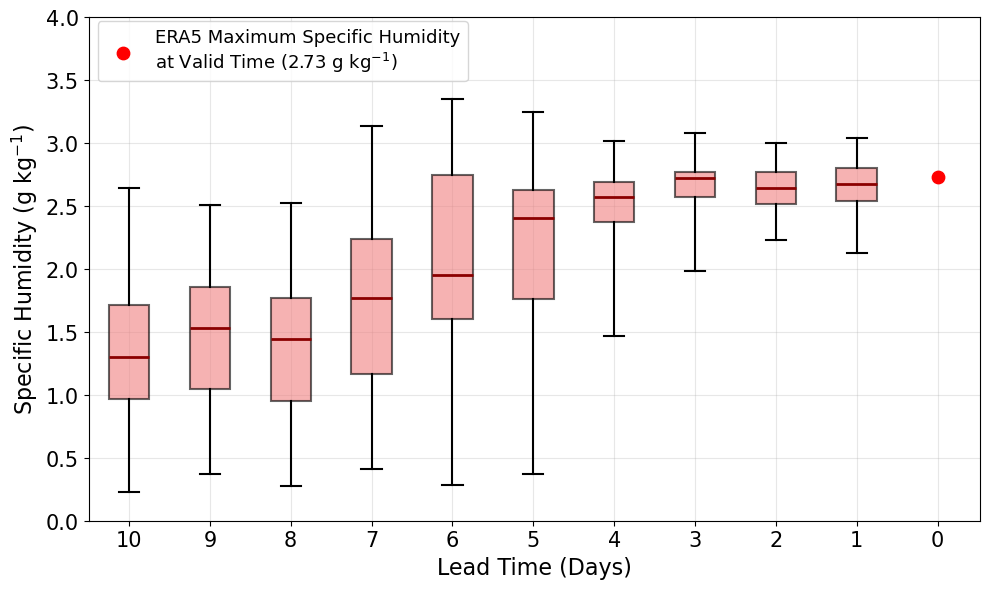

In [15]:
# Define search window around the ERA5 500 hPa maximum
search_radius_lat = 2.0  # ±2.0° latitude
search_radius_lon = 2.0  # ±2.0° longitude

lat_center = lat_max_500hPa_ERA5_pl
lon_center = lon_max_500hPa_ERA5_pl % 360

lat_min = lat_center - search_radius_lat
lat_max = lat_center + search_radius_lat

# Select 500 hPa specific humidity
ds_AIFS_500hPa_specific_humidity = ds_AIFS_pl[
    "specific_humidity_in_g_per_kg"
].sel(
    isobaricInhPa=500,
    method="nearest"
)

# Circular longitude distance, robust around 0°/360°
lon_distance = np.abs(
    (
        (
            ds_AIFS_500hPa_specific_humidity[
                "longitude"
            ]
            - lon_center
            + 180
        )
        % 360
    )
    - 180
)

# Extract specific humidity within the search window for all
# ensemble members and lead times
ds_AIFS_500hPa_search_window = (
    ds_AIFS_500hPa_specific_humidity.where(
        (
            (
                ds_AIFS_500hPa_specific_humidity[
                    "latitude"
                ]
                >= lat_min
            )
            & (
                ds_AIFS_500hPa_specific_humidity[
                    "latitude"
                ]
                <= lat_max
            )
            & (lon_distance <= search_radius_lon)
        ),
        drop=True
    )
)

# Find maximum specific humidity within the search window for
# each ensemble member and lead time
aifs_500hPa_specific_humidity_max_in_window = (
    ds_AIFS_500hPa_search_window.max(
        dim=["latitude", "longitude"]
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

# Use the actual lead-time coordinate
leadtimes = (
    aifs_500hPa_specific_humidity_max_in_window[
        "leadtime"
    ].values
)
n_leads = len(leadtimes)

# Convert lead-time labels to days when stored as timedelta64
if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (
        leadtimes / np.timedelta64(1, "D")
    ).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# Build one array per lead time, with longest lead time first
data_for_boxplot = []

for lt in leadtimes[::-1]:
    values = np.ravel(
        aifs_500hPa_specific_humidity_max_in_window
        .sel(leadtime=lt)
        .values
    )

    # Remove possible missing values
    values = values[np.isfinite(values)]
    data_for_boxplot.append(values)

box = ax.boxplot(
    data_for_boxplot,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightcoral",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkred",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum 500 hPa specific humidity
ax.scatter(
    n_leads + 1,
    specific_humidity_max_500hPa_ERA5_pl_value,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Specific Humidity\n"
        f"at Valid Time "
        f"({specific_humidity_max_500hPa_ERA5_pl_value:.2f} "
        "g kg$^{-1}$)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtime_days[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(
    aifs_500hPa_specific_humidity_max_in_window[
        "fc_valid_time"
    ].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel(
    "Specific Humidity (g kg$^{-1}$)",
    fontsize=16
)

# Fixed y-axis limits
specific_humidity_step = 0.5
specific_humidity_low = 0.0
specific_humidity_high = 4.0

ax.set_ylim(
    specific_humidity_low,
    specific_humidity_high
)

ax.set_yticks(
    np.arange(
        specific_humidity_low,
        specific_humidity_high + 0.1,
        specific_humidity_step
    )
)

ax.legend(
    fontsize=13,
    loc="upper left",
    bbox_to_anchor=(0.0, 1.01)
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_500hPa_AIFS_ERA5_max_spatial_allowance"
)

plt.show()
plt.close(fig)

#### **Difference Plot for 500 hPa Specific Humidity**


Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\03_specific_humidity\01_png\20260723_specific_humidity_difference_plot_500hPa_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\03_specific_humidity\02_pdf\20260723_specific_humidity_difference_plot_500hPa_AIFS_ERA5_leadtimes.pdf


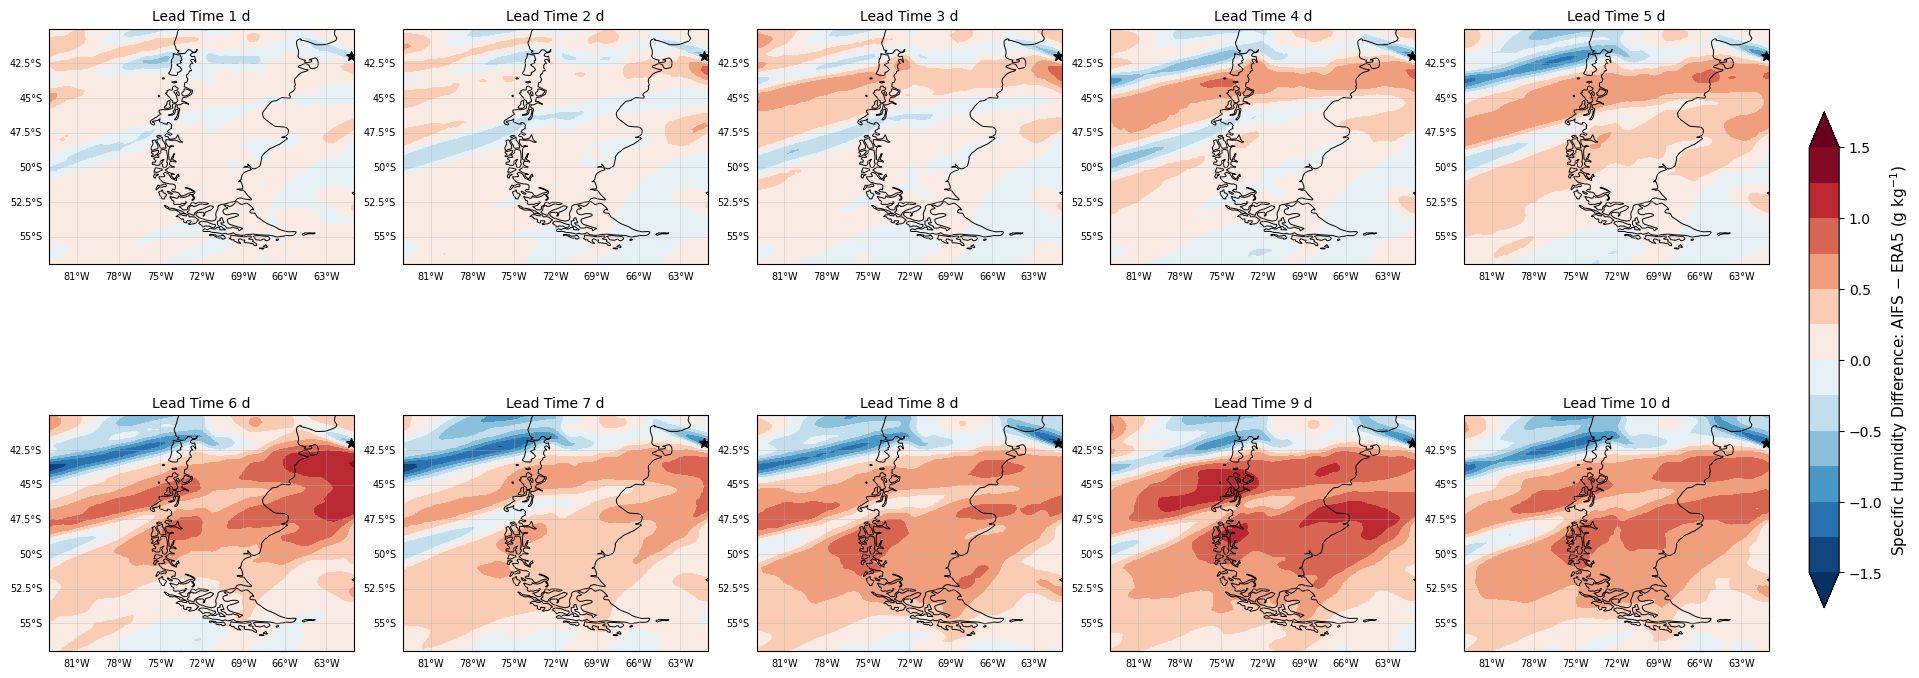

In [18]:
# 500 hPa specific humidity difference:
# AIFS ensemble mean minus ERA5
#
# Blue: AIFS ensemble mean is drier than ERA5
# Red:  AIFS ensemble mean is moister than ERA5

# ------------------------------------------------------------------
# Use the exact same spatial extent as the wind and temperature
# difference plots
# ------------------------------------------------------------------

common_lat_min_specific_humidity_diff = -57.0
common_lat_max_specific_humidity_diff = -40.0
common_lon_min_specific_humidity_diff = 277.0
common_lon_max_specific_humidity_diff = 299.0

# ------------------------------------------------------------------
# Select the AIFS 500 hPa specific humidity field on the common
# map domain
# ------------------------------------------------------------------

ds_AIFS_500_specific_humidity_diff = (
    ds_AIFS_pl["specific_humidity_in_g_per_kg"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .sel(
        latitude=slice(
            common_lat_max_specific_humidity_diff,
            common_lat_min_specific_humidity_diff
        ),
        longitude=slice(
            common_lon_min_specific_humidity_diff,
            common_lon_max_specific_humidity_diff
        )
    )
)

# ------------------------------------------------------------------
# AIFS ensemble mean
# ------------------------------------------------------------------

aifs_500_specific_humidity_ens_mean_diff = (
    ds_AIFS_500_specific_humidity_diff
    .mean(dim="ensemble_members")
    .sortby("leadtime")
    .squeeze(drop=True)
)

# ------------------------------------------------------------------
# Prepare ERA5 500 hPa specific humidity
# ------------------------------------------------------------------

era5_500_specific_humidity_diff = (
    ds_ERA5_pl["specific_humidity_in_g_per_kg"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze(drop=True)
    .assign_coords(
        longitude=(
            ds_ERA5_pl["longitude"] % 360
        )
    )
    .sortby("latitude")
    .sortby("longitude")
)

# ERA5 field on the displayed domain
era5_500_specific_humidity_domain_diff = (
    era5_500_specific_humidity_diff.where(
        (
            (
                era5_500_specific_humidity_diff.latitude
                >= common_lat_min_specific_humidity_diff
            )
            & (
                era5_500_specific_humidity_diff.latitude
                <= common_lat_max_specific_humidity_diff
            )
            & (
                era5_500_specific_humidity_diff.longitude
                >= common_lon_min_specific_humidity_diff
            )
            & (
                era5_500_specific_humidity_diff.longitude
                <= common_lon_max_specific_humidity_diff
            )
        ),
        drop=True
    )
)

# ------------------------------------------------------------------
# Interpolate ERA5 onto the AIFS grid
# ------------------------------------------------------------------

era5_500_specific_humidity_on_aifs_diff = (
    era5_500_specific_humidity_diff.interp(
        latitude=(
            aifs_500_specific_humidity_ens_mean_diff.latitude
        ),
        longitude=(
            aifs_500_specific_humidity_ens_mean_diff.longitude
        )
    )
)

# ------------------------------------------------------------------
# Calculate AIFS ensemble-mean minus ERA5 specific humidity
# difference
# ------------------------------------------------------------------

specific_humidity_500_difference = (
    aifs_500_specific_humidity_ens_mean_diff
    - era5_500_specific_humidity_on_aifs_diff
).transpose(
    "leadtime",
    "latitude",
    "longitude"
)

specific_humidity_500_difference.name = (
    "specific_humidity_500_difference"
)

# Check that the interpolation produced valid values
n_finite_500_specific_humidity_difference_values = int(
    np.isfinite(
        specific_humidity_500_difference.values
    ).sum()
)

if n_finite_500_specific_humidity_difference_values == 0:
    raise ValueError(
        "The ERA5-to-AIFS interpolation produced no "
        "finite values. Check the latitude and longitude "
        "coordinates."
    )

# ------------------------------------------------------------------
# Find the ERA5 maximum specific humidity within the displayed
# domain
# ------------------------------------------------------------------

era5_500_specific_humidity_stacked_diff = (
    era5_500_specific_humidity_domain_diff.stack(
        gridpoint=(
            "latitude",
            "longitude"
        )
    )
)

era5_500_specific_humidity_max_index_diff = int(
    era5_500_specific_humidity_stacked_diff.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_500_specific_humidity_max_point_diff = (
    era5_500_specific_humidity_stacked_diff.isel(
        gridpoint=(
            era5_500_specific_humidity_max_index_diff
        )
    )
)

era5_500_specific_humidity_max_value_diff = float(
    era5_500_specific_humidity_max_point_diff.values
)

era5_500_specific_humidity_max_lat_diff = float(
    era5_500_specific_humidity_max_point_diff[
        "latitude"
    ].values
)

era5_500_specific_humidity_max_lon_diff = float(
    era5_500_specific_humidity_max_point_diff[
        "longitude"
    ].values
)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes_500_specific_humidity_diff = (
    aifs_500_specific_humidity_ens_mean_diff[
        "leadtime"
    ].values
)

n_leadtimes_500_specific_humidity_diff = len(
    leadtimes_500_specific_humidity_diff
)

if n_leadtimes_500_specific_humidity_diff == 0:
    raise ValueError(
        "No AIFS lead times were found."
    )

if n_leadtimes_500_specific_humidity_diff > 10:
    raise ValueError(
        "The 2 × 5 layout supports a maximum of "
        "10 AIFS lead times."
    )

if np.issubdtype(
    leadtimes_500_specific_humidity_diff.dtype,
    np.timedelta64
):
    leadtime_days_500_specific_humidity_diff = (
        leadtimes_500_specific_humidity_diff
        / np.timedelta64(1, "D")
    ).astype(int)

else:
    leadtime_days_500_specific_humidity_diff = (
        leadtimes_500_specific_humidity_diff.astype(int)
    )

# ------------------------------------------------------------------
# Create one common symmetric specific-humidity-difference scale
# ------------------------------------------------------------------

difference_abs_max_500_specific_humidity = float(
    np.abs(
        specific_humidity_500_difference
    ).max(
        skipna=True
    ).compute().values
)

if not np.isfinite(
    difference_abs_max_500_specific_humidity
):
    raise ValueError(
        "The 500 hPa specific humidity difference contains "
        "no finite values."
    )

# Use 0.25 g kg^-1 intervals
difference_step_500_specific_humidity = 0.25

# Round upward to the next multiple of 0.25 g kg^-1
difference_limit_500_specific_humidity = max(
    difference_step_500_specific_humidity,
    float(
        difference_step_500_specific_humidity
        * np.ceil(
            difference_abs_max_500_specific_humidity
            / difference_step_500_specific_humidity
        )
    )
)

difference_levels_500_specific_humidity = np.arange(
    -difference_limit_500_specific_humidity,
    difference_limit_500_specific_humidity
    + difference_step_500_specific_humidity,
    difference_step_500_specific_humidity
)

# ------------------------------------------------------------------
# Create figure: 2 rows × 5 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 8),
    subplot_kw={
        "projection": map_projection
    }
)

axes = axes.flatten()

fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.08,
    top=0.95,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# Difference panels
# ------------------------------------------------------------------

for i, lt in enumerate(
    leadtimes_500_specific_humidity_diff
):
    ax = axes[i]

    difference_500_specific_humidity_sel = (
        specific_humidity_500_difference.sel(
            leadtime=lt
        )
    )

    ax.set_extent(
        [
            common_lon_min_specific_humidity_diff,
            common_lon_max_specific_humidity_diff,
            common_lat_min_specific_humidity_diff,
            common_lat_max_specific_humidity_diff
        ],
        crs=map_projection
    )

    # Specific humidity difference background
    cf_500_specific_humidity_diff = ax.contourf(
        difference_500_specific_humidity_sel.longitude,
        difference_500_specific_humidity_sel.latitude,
        difference_500_specific_humidity_sel,
        levels=(
            difference_levels_500_specific_humidity
        ),
        cmap="RdBu_r",
        extend="both",
        transform=map_projection
    )

    # ERA5 maximum specific humidity location
    ax.scatter(
        era5_500_specific_humidity_max_lon_diff,
        era5_500_specific_humidity_max_lat_diff,
        marker="*",
        color="black",
        s=50,
        transform=map_projection,
        zorder=6
    )

    # Coastlines
    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"Lead Time "
        f"{leadtime_days_500_specific_humidity_diff[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 7
    }

    gl.ylabel_style = {
        "size": 7
    }

    gl.xpadding = 5
    gl.ypadding = 5

# Hide unused panels if fewer than ten lead times exist
for panel_index in range(
    n_leadtimes_500_specific_humidity_diff,
    len(axes)
):
    axes[
        panel_index
    ].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,
    0.18,
    0.015,
    0.62
])

cbar = fig.colorbar(
    cf_500_specific_humidity_diff,
    cax=cbar_ax,
    boundaries=(
        difference_levels_500_specific_humidity
    ),
    spacing="proportional",
    extend="both",
    extendfrac="auto"
)

cbar.set_label(
    "Specific Humidity Difference: "
    "AIFS − ERA5 (g kg$^{-1}$)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# ------------------------------------------------------------------
# Save and display
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "difference_plot_500hPa_AIFS_ERA5_leadtimes"
)

plt.show()
plt.close(fig)
